# Notebook 2.1 — Watershed Clustering Analysis

## Objective

Group the 19 watersheds using two independent clustering criteria based on physical properties:

| Criterion | Variables |
|---|---|
| **CN** (Curve Number) | `CN_ponderado`, `CN_DT`, `n`, `DT_n`, `area_cuenca`, `longitud_total`, `z_min`, `z_max` |
| **GA** (Green-Ampt) | `mean_ks`, `DT_ks`, `mean_thetas`, `DT_thetas`, `mean_thetar`, `DT_thetar`, `mean_thau`, `DT_thau`, `area_cuenca`, `longitud_total`, `z_min`, `z_max` |

### Cluster Configuration

**CN Groups (3 clusters):**
- Cluster 0: FlamisellCabdella, VallfarreraAlins
- Cluster 1: IzalzuAnduña, BailinSabiñanigo, UrriobiEspinal, UbaguaRiezu, ZatoyaOchagavia, ZidacosGarinoiain
- Cluster 2: DezaEmbidDeAriza, GaronaBossost, IsuelaTrasobares, NelaVillarcayo, OroncilloOron, RudronValdelateja, SanguesaOnsella, TironSanMiguelPedroso, TruebaMedinaDePomar, CidacosYanguas, SubialdeLarrinoa

**GA Groups (2 clusters):**
- Cluster 0: OroncilloOron, FlamisellCabdella, GaronaBossost, TruebaMedinaDePomar
- Cluster 1: IzalzuAnduña, DezaEmbidDeAriza, NelaVillarcayo, RudronValdelateja, SanguesaOnsella, SubialdeLarrinoa, TironSanMiguelPedroso, UrriobiEspinal, UbaguaRiezu, ZatoyaOchagavia, ZidacosGarinoiain, BailinSabiñanigo, IsuelaTrasobares, VallfarreraAlins, CidacosYanguas

### Analysis Performed
- Hierarchical clustering dendrogram (Ward linkage)
- 2D PCA visualization
- Heatmap of watershed characteristics

### Outputs
- `data/processed/cluster_assignments_forced.csv` — cluster assignments per watershed
- `notebooks/output/2_1-forced-clustering/` — figures

## Imports and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist

warnings.filterwarnings('ignore')

# Configure matplotlib for publication-quality figures
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['lines.linewidth'] = 1.5

RAW_PATH  = '../../data/raw/'
PROC_PATH = '../../data/processed/'
OUT_PATH  = '../output/2_1-forced-clustering/'

os.makedirs(OUT_PATH, exist_ok=True)

RANDOM_STATE = 42
print('Setup complete.')

Setup complete.


## Load Physical Properties

In [2]:
df_phys = pd.read_csv(os.path.join(RAW_PATH, 'cuencas_unificadas.csv'), index_col='cuenca')

print(f'Watersheds: {len(df_phys)}')
print(f'Variables: {list(df_phys.columns)}')
display(df_phys.head())

Watersheds: 19
Variables: ['CN_ponderado', 'CN_DT', 'n', 'DT_n', 'area_cuenca', 'longitud_total', 'z_min', 'z_max', 'mean_sand', 'mean_silt', 'mean_clay', 'soil_type', 'ks_st', 'thetas_st', 'thetar_st', 'thau_st', 'swcfc_st', 'swcpwp_st', 'mean_ks', 'DT_ks', 'mean_thetas', 'DT_thetas', 'mean_thetar', 'DT_thetar', 'mean_thau', 'DT_thau', 'mean_swcfc', 'DT_swcfc', 'mean_swcpwp', 'DT_swcpwp', 'lon_min', 'lon_max', 'lat_min', 'lat_max', 'x_min_25830', 'x_max_25830', 'y_min_25830', 'y_max_25830']


,CN_ponderado,CN_DT,n,DT_n,area_cuenca,longitud_total,z_min,z_max,mean_sand,mean_silt,...,mean_swcpwp,DT_swcpwp,lon_min,lon_max,lat_min,lat_max,x_min_25830,x_max_25830,y_min_25830,y_max_25830
cuenca,,,,,,,,,,,,,,,,,,,,,
Anduña,83.119653,6.103479,0.040012,0.050471,4.716346e+07,12066.232638,796.466980,1725.098022,33.836697,41.072061,...,0.136612,0.038326,-1.058280,-0.957470,42.882873,42.975849,658569.0,666551.0,4749637.0,4.760157e+06
Bailin,82.394983,6.965180,0.041736,0.054148,4.509884e+06,4651.442277,743.674988,1243.829956,33.596698,43.294840,...,0.115188,0.000000,-0.371245,-0.325385,42.469897,42.490555,716105.0,719803.0,4705299.0,4.707711e+06
Deza,84.258194,5.172985,0.040531,0.042850,2.073666e+08,40193.027884,780.075989,1313.410034,37.059341,37.922089,...,0.138183,0.039249,-2.204975,-1.956204,41.382595,41.624938,566475.0,586951.0,4581535.0,4.608661e+06
Flamisell,84.836084,6.495779,0.114143,0.030173,6.765123e+07,17336.719144,1275.260010,2962.366943,34.749750,42.171810,...,0.122798,0.029699,0.916032,1.029439,42.440430,42.555635,328602.5,338227.5,4700782.5,4.713352e+06
Garona,82.696013,6.323385,0.087235,0.040698,4.164450e+08,47696.308032,0.000000,3007.321045,35.091156,41.322673,...,0.123962,0.027550,0.660431,1.008805,42.583798,42.818310,308019.0,337221.0,4717251.0,4.742562e+06


In [3]:
# Mapping: short name (cuencas_unificadas.csv) -> full name
CUENCA_TO_NOMBRE = {
    'Anduña':      'IzalzuAnduña',
    'Bailin':      'BailinSabiñanigo',
    'Deza':        'DezaEmbidDeAriza',
    'Flamisell':   'FlamisellCabdella',
    'Garona':      'GaronaBossost',
    'Isuela':      'IsuelaTrasobares',
    'Nela':        'NelaVillarcayo',
    'Oroncillo':   'OroncilloOron',
    'Rudron':      'RudronValdelateja',
    'Sangüesa':    'SanguesaOnsella',
    'Subialde':    'SubialdeLarrinoa',
    'Tiron':       'TironSanMiguelPedroso',
    'Trueba':      'TruebaMedinaDePomar',
    'Ubagua':      'UbaguaRiezu',
    'Urrobi':      'UrriobiEspinal',
    'Vallfarrera': 'VallfarreraAlins',
    'Yanguas':     'CidacosYanguas',
    'Zatoya':      'ZatoyaOchagavia',
    'Zidacos':     'ZidacosGarinoiain',
}

# Rename index to full names
df_phys.index = df_phys.index.map(CUENCA_TO_NOMBRE)
df_phys.index.name = 'watershed'

print('Index renamed to full watershed names:')
print(df_phys.index.tolist())

Index renamed to full watershed names:
['IzalzuAnduña', 'BailinSabiñanigo', 'DezaEmbidDeAriza', 'FlamisellCabdella', 'GaronaBossost', 'IsuelaTrasobares', 'NelaVillarcayo', 'OroncilloOron', 'RudronValdelateja', 'SanguesaOnsella', 'SubialdeLarrinoa', 'TironSanMiguelPedroso', 'TruebaMedinaDePomar', 'UrriobiEspinal', 'UbaguaRiezu', 'VallfarreraAlins', 'CidacosYanguas', 'ZatoyaOchagavia', 'ZidacosGarinoiain']


## Define Cluster Assignments

In [4]:
# CN cluster assignments
CLUSTERS_CN = {
    0: ['FlamisellCabdella', 'VallfarreraAlins'],
    1: ['IzalzuAnduña', 'BailinSabiñanigo', 'UrriobiEspinal', 
        'UbaguaRiezu', 'ZatoyaOchagavia', 'ZidacosGarinoiain'],
    2: ['DezaEmbidDeAriza', 'GaronaBossost', 'IsuelaTrasobares', 
        'NelaVillarcayo', 'OroncilloOron', 'RudronValdelateja', 
        'SanguesaOnsella', 'TironSanMiguelPedroso', 'TruebaMedinaDePomar', 
        'CidacosYanguas', 'SubialdeLarrinoa']
}

# GA cluster assignments
CLUSTERS_GA = {
    0: ['OroncilloOron', 'FlamisellCabdella', 'GaronaBossost', 'TruebaMedinaDePomar'],
    1: ['IzalzuAnduña', 'DezaEmbidDeAriza', 'NelaVillarcayo', 'RudronValdelateja', 
        'SanguesaOnsella', 'SubialdeLarrinoa', 'TironSanMiguelPedroso', 
        'UrriobiEspinal', 'UbaguaRiezu', 'ZatoyaOchagavia', 'ZidacosGarinoiain',
        'BailinSabiñanigo', 'IsuelaTrasobares', 'VallfarreraAlins', 'CidacosYanguas']
}

# Create mapping: watershed -> cluster
def create_cluster_map(clusters_dict):
    mapping = {}
    for cluster_id, watersheds in clusters_dict.items():
        for watershed in watersheds:
            mapping[watershed] = cluster_id
    return mapping

CN_MAP = create_cluster_map(CLUSTERS_CN)
GA_MAP = create_cluster_map(CLUSTERS_GA)

print(f'CN clusters: {len(CLUSTERS_CN)} groups')
for k, v in CLUSTERS_CN.items():
    print(f"  Group {k}: {len(v)} watersheds")

print(f'\nGA clusters: {len(CLUSTERS_GA)} groups')
for k, v in CLUSTERS_GA.items():
    print(f"  Group {k}: {len(v)} watersheds")

CN clusters: 3 groups
  Group 0: 2 watersheds
  Group 1: 6 watersheds
  Group 2: 11 watersheds

GA clusters: 2 groups
  Group 0: 4 watersheds
  Group 1: 15 watersheds


## Define Variables by Criterion

In [5]:
VARS_CN = [
    'CN_ponderado', 'CN_DT', 'n', 'DT_n',
    'area_cuenca', 'longitud_total', 'z_min', 'z_max'
]

VARS_GA = [
    'mean_ks', 'DT_ks',
    'mean_thetas', 'DT_thetas',
    'mean_thetar', 'DT_thetar',
    'mean_thau', 'DT_thau',
    'area_cuenca', 'longitud_total', 'z_min', 'z_max'
]

# Verify variables exist
for v in VARS_CN:
    assert v in df_phys.columns, f'CN variable not found: {v}'
for v in VARS_GA:
    assert v in df_phys.columns, f'GA variable not found: {v}'

print(f'CN variables ({len(VARS_CN)}): {VARS_CN}')
print(f'GA variables ({len(VARS_GA)}): {VARS_GA}')

CN variables (8): ['CN_ponderado', 'CN_DT', 'n', 'DT_n', 'area_cuenca', 'longitud_total', 'z_min', 'z_max']
GA variables (12): ['mean_ks', 'DT_ks', 'mean_thetas', 'DT_thetas', 'mean_thetar', 'DT_thetar', 'mean_thau', 'DT_thau', 'area_cuenca', 'longitud_total', 'z_min', 'z_max']


## Clustering Analysis Function

This function generates all clustering visualizations for a given criterion.

In [6]:
def run_clustering_analysis(df, variables, criterion, cluster_map, 
                            out_dir=OUT_PATH, random_state=42):
    """
    Complete clustering visualization pipeline.

    Parameters
    ----------
    df : pd.DataFrame, index = watershed name
    variables : list of str
    criterion : str  (e.g., 'CN' or 'GA')
    cluster_map : dict  {watershed: cluster_id}
    out_dir : str
    random_state : int

    Returns
    -------
    dict with 'labels', 'df_result'
    """
    print('='*70)
    print(f' CRITERION: {criterion}')
    print('='*70)

    # Color palette for clusters - professional colors for doctoral thesis
    COLORS = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', '#1ABC9C']
    
    # -------------------------------------------------------------------------
    # 1. Scale data
    # -------------------------------------------------------------------------
    X = df[variables].copy()
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # -------------------------------------------------------------------------
    # 2. Assign clusters
    # -------------------------------------------------------------------------
    labels = np.array([cluster_map[name] for name in df.index])
    n_clusters = len(np.unique(labels))
    
    df_result = df[variables].copy()
    df_result[f'cluster_{criterion}'] = labels

    print(f'\n  Number of clusters: {n_clusters}')
    for c in sorted(np.unique(labels)):
        basins = df.index[labels == c].tolist()
        print(f'    Cluster {c}: {len(basins)} watersheds')

    # -------------------------------------------------------------------------
    # 3. Hierarchical clustering dendrogram
    # -------------------------------------------------------------------------
    linkage_matrix = linkage(X_scaled, method='ward')
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    # Create dendrogram
    dend = dendrogram(
        linkage_matrix,
        labels=df.index.tolist(),
        leaf_rotation=90,
        leaf_font_size=10,
        ax=ax,
        color_threshold=0,
        above_threshold_color='#34495E'
    )
    
    # Color leaves by clusters
    xlabels = ax.get_xmajorticklabels()
    for lbl in xlabels:
        watershed_name = lbl.get_text()
        cluster_id = cluster_map.get(watershed_name, 0)
        lbl.set_color(COLORS[cluster_id % len(COLORS)])
        lbl.set_weight('normal')
        lbl.set_fontsize(10)
    
    ax.set_title(f'Hierarchical Dendrogram (Ward Linkage) — {criterion} Criterion', 
                 fontsize=13, weight='normal', pad=15)
    ax.set_xlabel('Watershed', fontsize=11)
    ax.set_ylabel('Euclidean Distance', fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=COLORS[i], 
                             edgecolor='black',
                             linewidth=0.8,
                             label=f'Cluster {i}') 
                      for i in range(n_clusters)]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=10, 
             frameon=True, fancybox=False, edgecolor='black')
    
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'{criterion.lower()}_dendrogram.png'), 
                dpi=300, bbox_inches='tight')
    plt.show()

    # -------------------------------------------------------------------------
    # 4. PCA 2D scatter plot with numbered watersheds
    # -------------------------------------------------------------------------
    pca = PCA(n_components=2, random_state=random_state)
    X_pca = pca.fit_transform(X_scaled)
    var_exp = pca.explained_variance_ratio_ * 100

    fig, ax = plt.subplots(figsize=(12, 9))
    
    # Create watershed ID mapping for legend
    watershed_ids = {name: i+1 for i, name in enumerate(df.index)}
    
    # Plot points with numbers instead of names to avoid overlapping
    for i, (basin, label) in enumerate(zip(df.index, labels)):
        color = COLORS[int(label) % len(COLORS)]
        ax.scatter(X_pca[i, 0], X_pca[i, 1], 
                  c=color, s=200, edgecolors='black', linewidths=1.5, 
                  alpha=0.85, zorder=10)
        # Add number on point
        ax.text(X_pca[i, 0], X_pca[i, 1], str(i+1), 
               ha='center', va='center', fontsize=11, 
               weight='bold', color='black', zorder=11)
    
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}% explained variance)', fontsize=12)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}% explained variance)', fontsize=12)
    ax.set_title(f'PCA Biplot — {criterion} Criterion', 
                fontsize=13, weight='normal', pad=15)
    ax.grid(True, alpha=0.25, linestyle=':', linewidth=0.8, color='gray')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Create comprehensive legend with watershed names
    legend_text = '\n'.join([f'{watershed_ids[name]:2d}. {name} (C{cluster_map[name]})' 
                            for name in df.index])
    ax.text(1.02, 0.5, legend_text, transform=ax.transAxes,
           fontsize=8, verticalalignment='center',
           bbox=dict(boxstyle='round,pad=0.8', facecolor='white', 
                    edgecolor='black', linewidth=0.8, alpha=0.95),
           family='monospace')
    
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'{criterion.lower()}_pca.png'), 
                dpi=300, bbox_inches='tight')
    plt.show()

    # -------------------------------------------------------------------------
    # 5. Heatmap of characteristics by cluster
    # -------------------------------------------------------------------------
    df_heatmap = df[variables].copy()
    df_heatmap['cluster'] = labels
    df_heatmap_sorted = df_heatmap.sort_values('cluster')

    # Z-score for comparability
    from sklearn.preprocessing import StandardScaler as SS
    vals_z = SS().fit_transform(df_heatmap_sorted[variables])
    df_z = pd.DataFrame(vals_z, index=df_heatmap_sorted.index, columns=variables)

    # Create row colors for clusters
    cluster_colors = df_heatmap_sorted['cluster'].map(
        {i: COLORS[i % len(COLORS)] for i in range(n_clusters)}
    )
    
    fig, ax = plt.subplots(figsize=(len(variables)*0.8 + 3, 12))
    
    sns.heatmap(
        df_z, annot=True, fmt='.2f',
        cmap='RdBu_r', center=0, linewidths=0.8, linecolor='white',
        ax=ax,
        cbar_kws={'label': 'Standardized Value (Z-score)', 'shrink': 0.8},
        yticklabels=df_z.index,
        annot_kws={'fontsize': 8}
    )
    
    # Add cluster color bar on the left
    for idx, (watershed, color) in enumerate(cluster_colors.items()):
        ax.add_patch(plt.Rectangle((-0.6, idx), 0.4, 1, 
                                   facecolor=color, edgecolor='black', 
                                   linewidth=0.8, transform=ax.transData, 
                                   clip_on=False))
    
    ax.set_title(f'Watershed Characteristics Heatmap — {criterion} Criterion', 
                fontsize=13, weight='normal', pad=20)
    ax.set_xlabel('Physical Variables', fontsize=11)
    ax.set_ylabel('Watershed', fontsize=11)
    
    # Rotate x labels for readability
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    
    # Add cluster legend
    legend_elements = [Patch(facecolor=COLORS[i], 
                             label=f'Cluster {i}', 
                             edgecolor='black',
                             linewidth=0.8) 
                      for i in range(n_clusters)]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.18, 1), 
             fontsize=10, title='Cluster', title_fontsize=11,
             frameon=True, fancybox=False, edgecolor='black')
    
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'{criterion.lower()}_heatmap.png'), 
                dpi=300, bbox_inches='tight')
    plt.show()

    return {
        'labels': labels,
        'df_result': df_result,
        'pca': pca,
        'scaler': scaler,
        'variables': variables
    }


## CN Criterion Clustering

 CRITERION: CN

  Number of clusters: 3
    Cluster 0: 2 watersheds
    Cluster 1: 6 watersheds
    Cluster 2: 11 watersheds


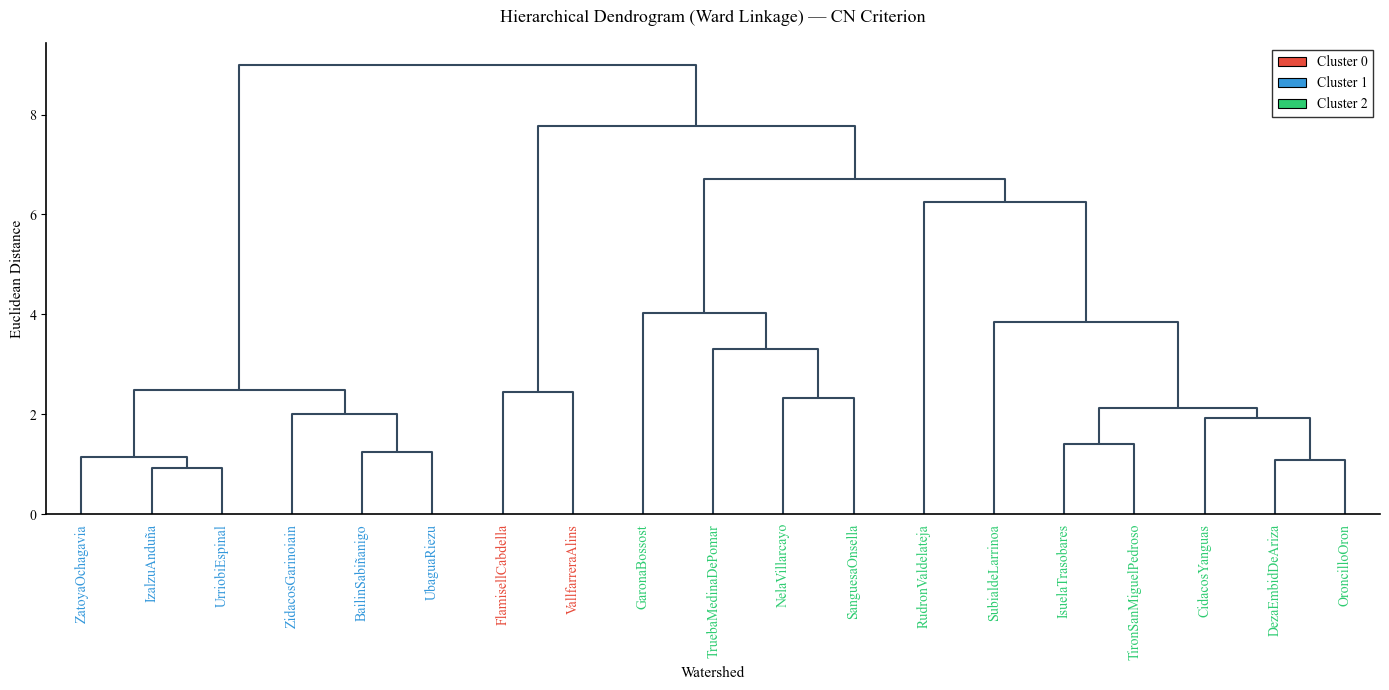

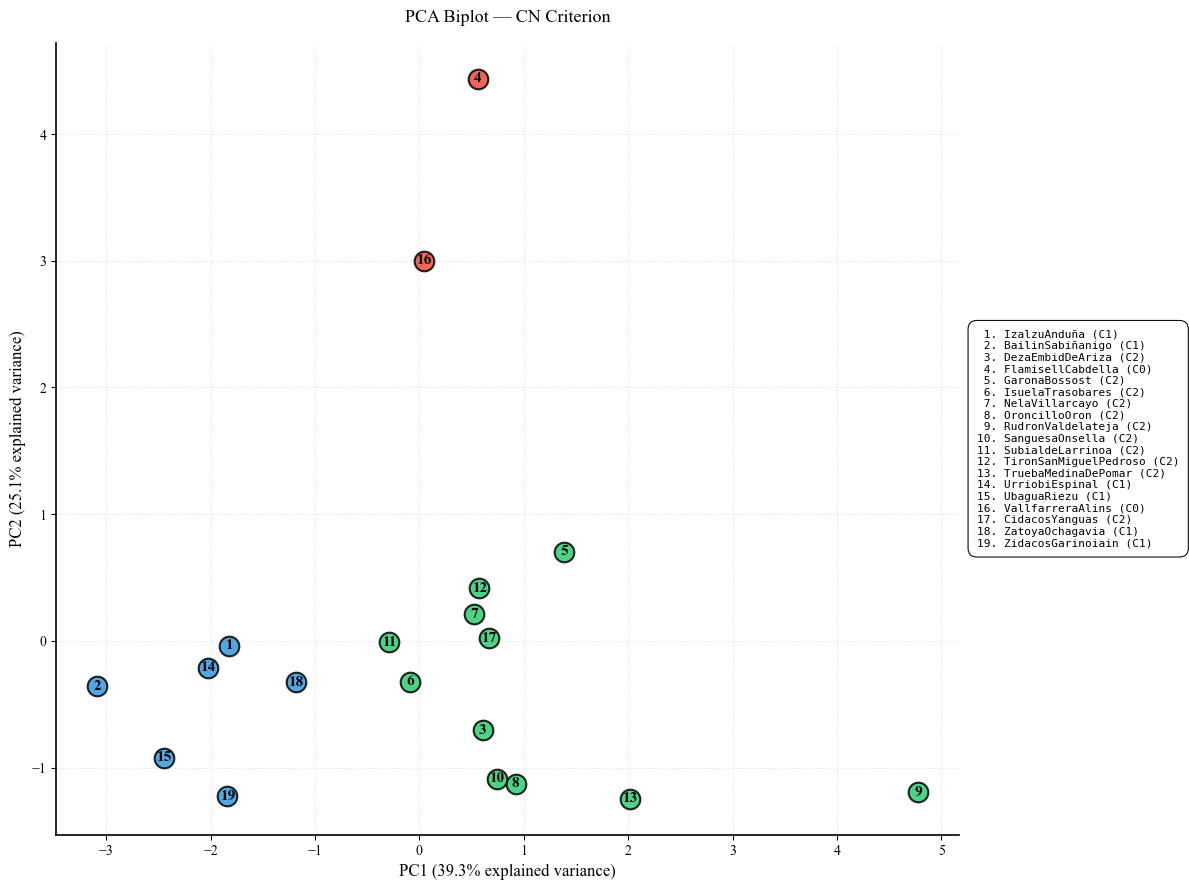

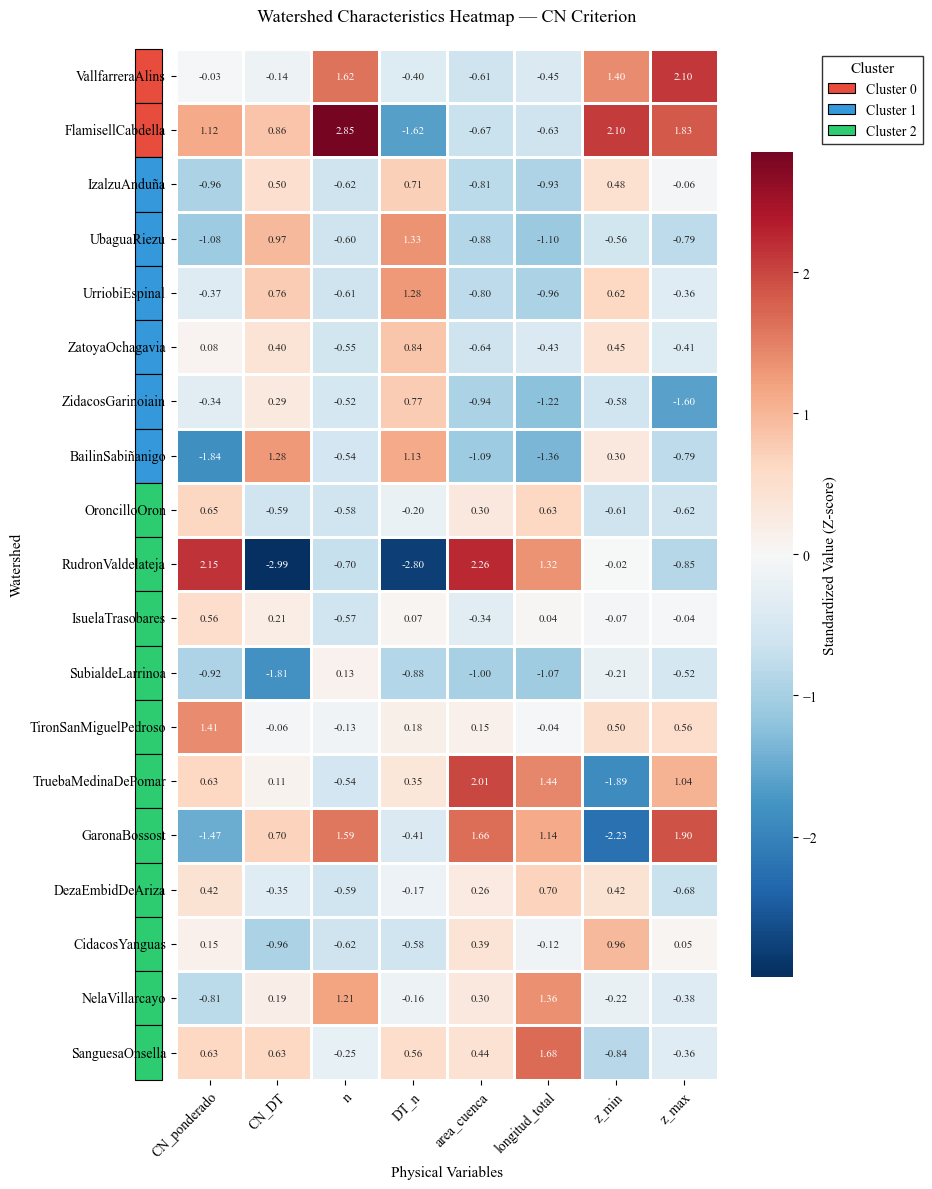

In [7]:
result_cn = run_clustering_analysis(
    df=df_phys,
    variables=VARS_CN,
    criterion='CN',
    cluster_map=CN_MAP
)

## GA Criterion Clustering

 CRITERION: GA

  Number of clusters: 2
    Cluster 0: 4 watersheds
    Cluster 1: 15 watersheds


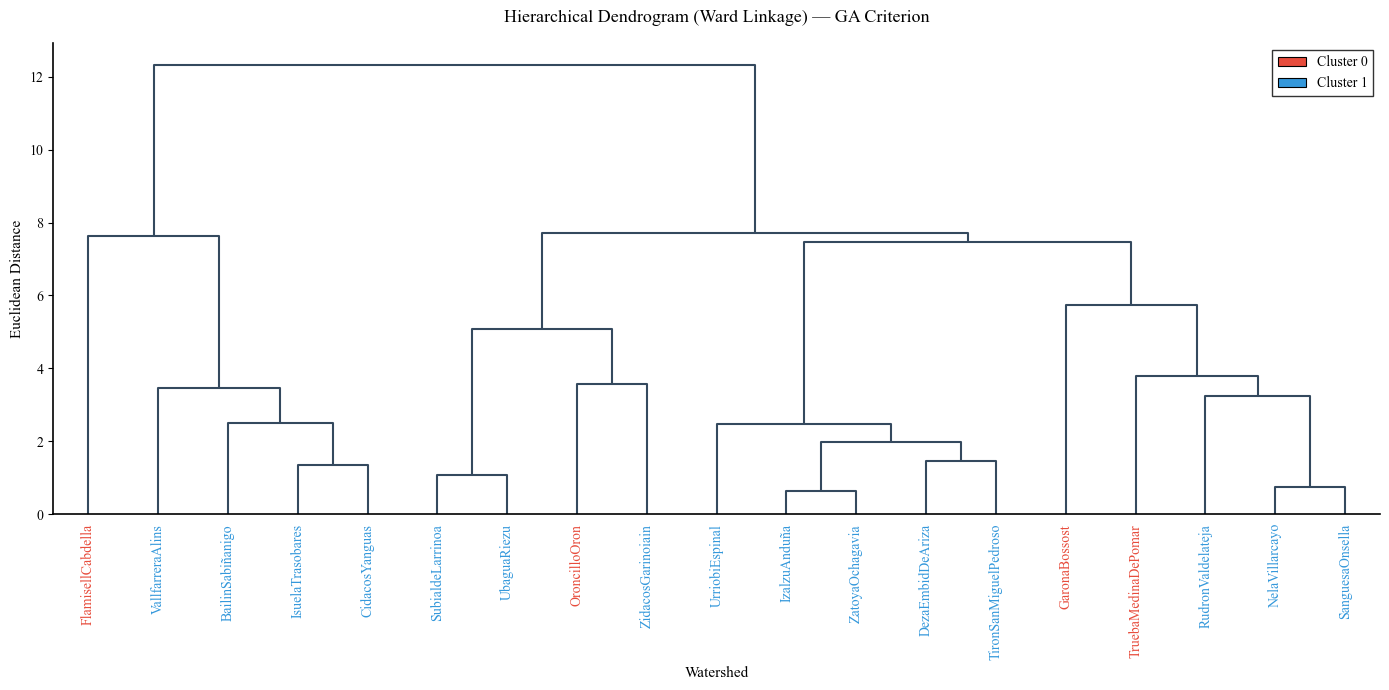

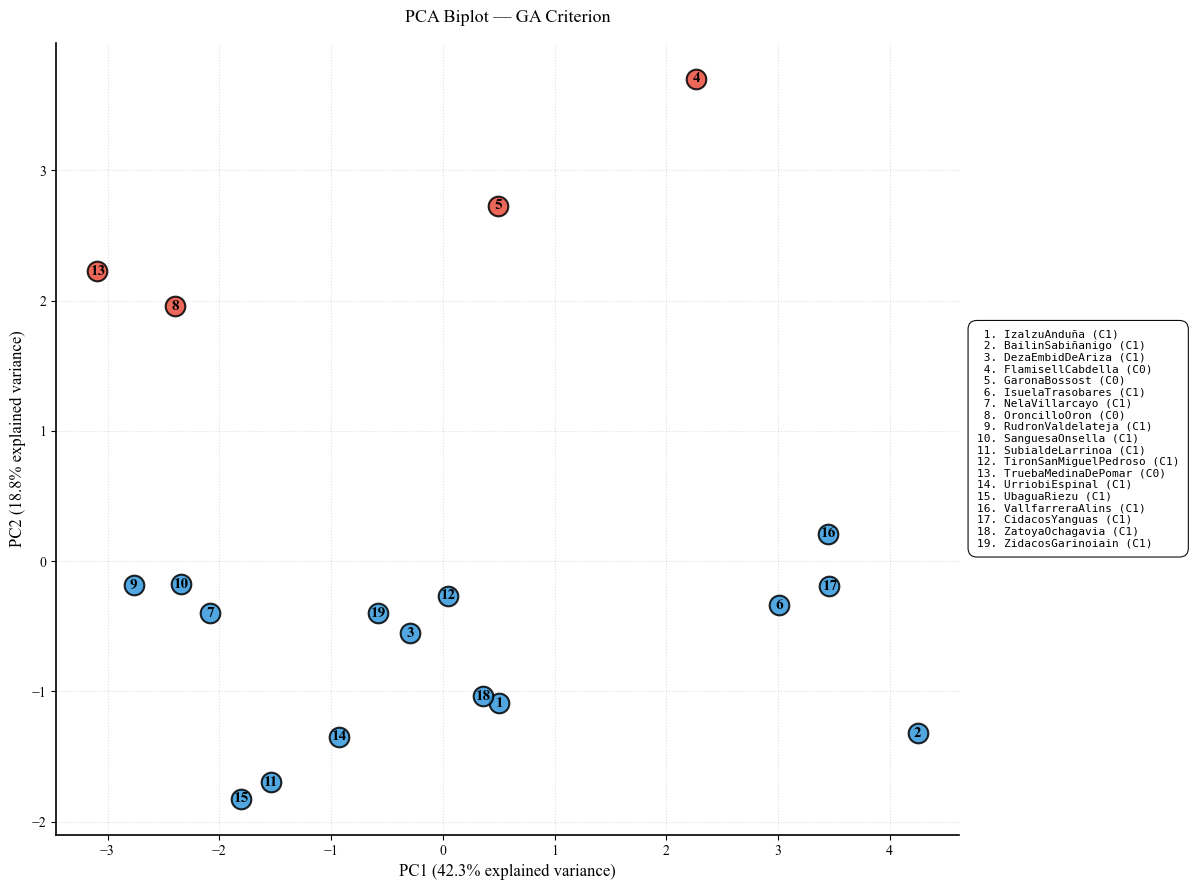

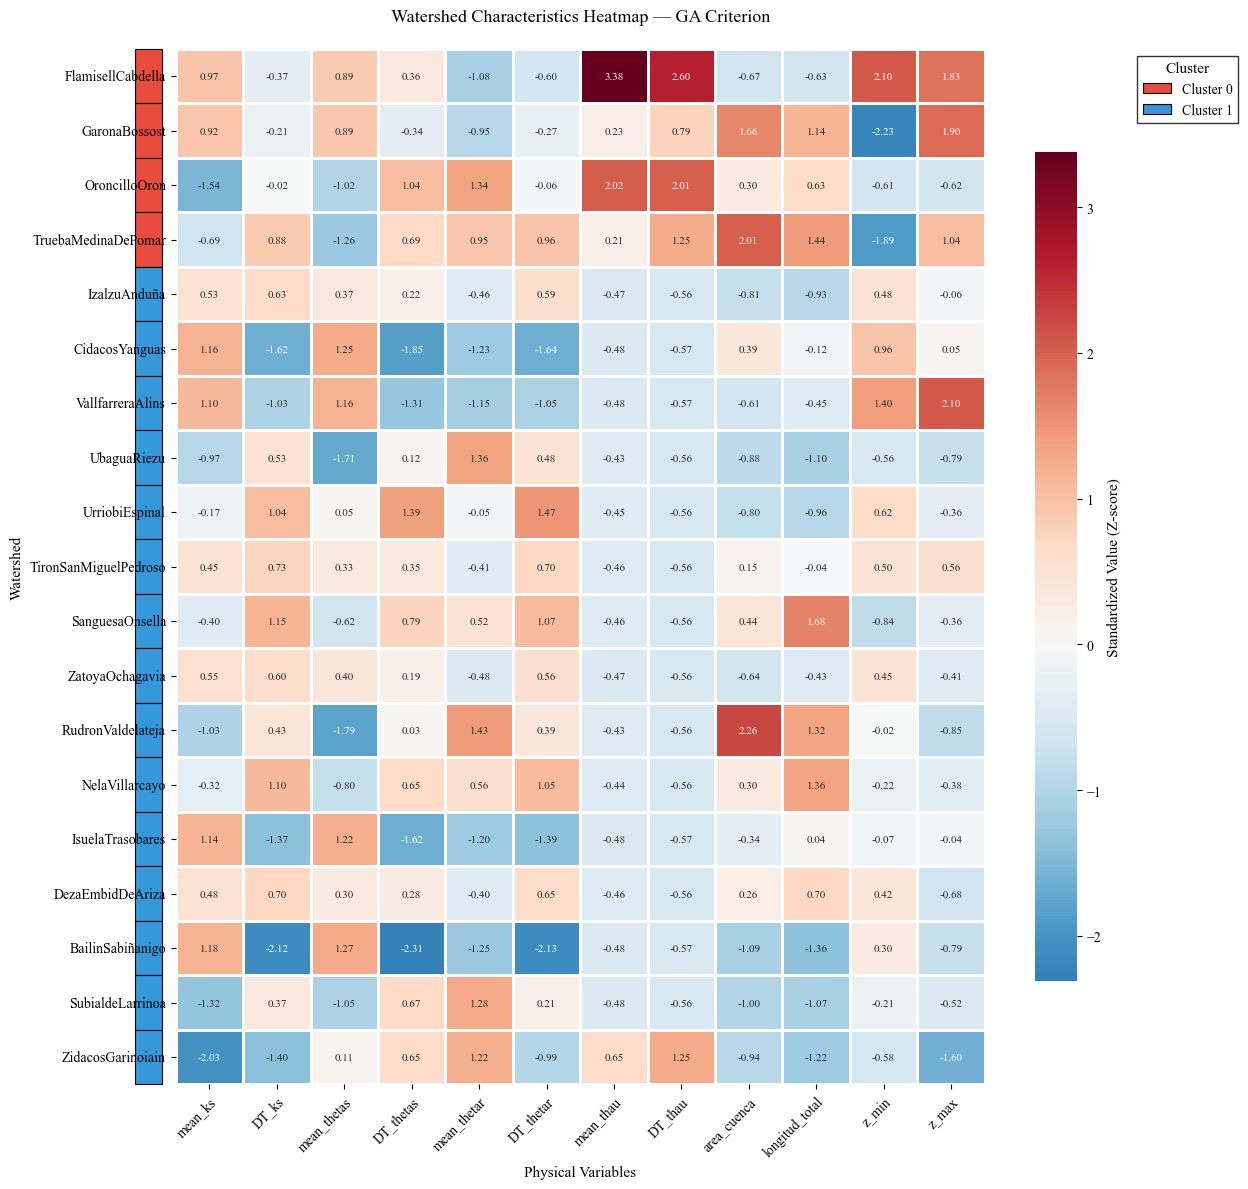

In [8]:
result_ga = run_clustering_analysis(
    df=df_phys,
    variables=VARS_GA,
    criterion='GA',
    cluster_map=GA_MAP
)

## Comparative Summary

In [9]:
# Assignment table
df_assignments = pd.DataFrame(index=df_phys.index)
df_assignments['cluster_CN'] = result_cn['labels']
df_assignments['cluster_GA'] = result_ga['labels']

display(df_assignments)

print(f'\nCN clusters: {df_assignments["cluster_CN"].nunique()}')
print(f'GA clusters: {df_assignments["cluster_GA"].nunique()}')

,cluster_CN,cluster_GA
watershed,,
IzalzuAnduña,1,1
BailinSabiñanigo,1,1
DezaEmbidDeAriza,2,1
FlamisellCabdella,0,0
GaronaBossost,2,0
IsuelaTrasobares,2,1
NelaVillarcayo,2,1
OroncilloOron,2,0
RudronValdelateja,2,1



CN clusters: 3
GA clusters: 2


## CN vs GA Comparison Visualization

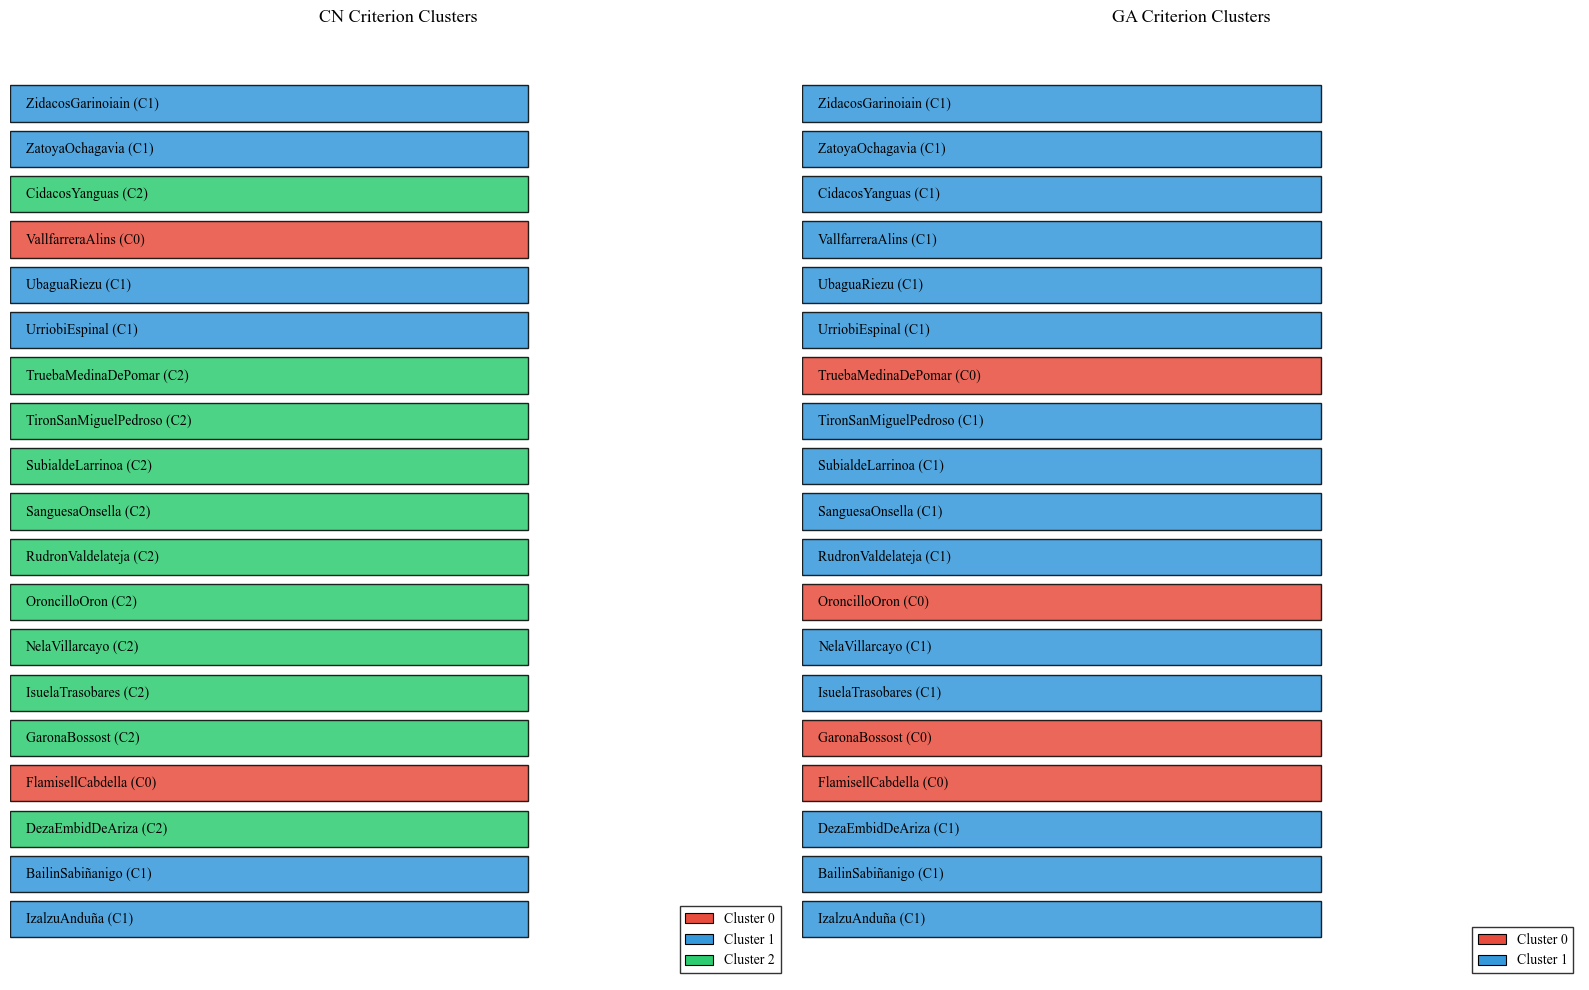

In [10]:
# CN vs GA comparison (horizontal bars)
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

COLORS = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', '#1ABC9C']

for ax, col, title in zip(
    axes,
    ['cluster_CN', 'cluster_GA'],
    ['CN Criterion Clusters', 'GA Criterion Clusters']
):
    n_clusters = df_assignments[col].nunique()
    
    for i, (watershed, row) in enumerate(df_assignments.iterrows()):
        c = row[col]
        ax.barh(i, 1, color=COLORS[int(c) % len(COLORS)], 
               edgecolor='black', linewidth=1.0, alpha=0.85)
        ax.text(0.03, i, f'{watershed} (C{int(c)})', 
               va='center', fontsize=10, weight='normal')
    
    ax.set_xlim(0, 1.5)
    ax.set_yticks([])
    ax.set_xlabel('', fontsize=11)
    ax.set_title(title, fontsize=13, weight='normal', pad=15)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.set_xticks([])
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=COLORS[i % len(COLORS)], 
                             label=f'Cluster {i}', 
                             edgecolor='black',
                             linewidth=0.8) 
                      for i in range(n_clusters)]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=10,
             frameon=True, fancybox=False, edgecolor='black')

plt.tight_layout()
plt.savefig(os.path.join(OUT_PATH, 'comparison_cn_ga.png'), 
           dpi=300, bbox_inches='tight')
plt.show()

## Save Cluster Assignments

In [11]:
out_path = os.path.join(PROC_PATH, 'cluster_assignments_forced.csv')
df_assignments.to_csv(out_path, index_label='watershed')
print(f'Cluster assignments saved to: {out_path}')
display(df_assignments)

Cluster assignments saved to: ../../data/processed/cluster_assignments_forced.csv


,cluster_CN,cluster_GA
watershed,,
IzalzuAnduña,1,1
BailinSabiñanigo,1,1
DezaEmbidDeAriza,2,1
FlamisellCabdella,0,0
GaronaBossost,2,0
IsuelaTrasobares,2,1
NelaVillarcayo,2,1
OroncilloOron,2,0
RudronValdelateja,2,1


## Summary

This notebook has generated visualizations for watershed clustering using two hydrological criteria (CN and GA).

### Key Results:
- **CN Criterion**: 3 clusters based on Curve Number model variables
- **GA Criterion**: 2 clusters based on Green-Ampt model variables
- Dendrograms illustrate the hierarchical structure of watersheds
- PCA biplots reveal the spatial distribution in reduced feature space
- Heatmaps show characteristic patterns within each cluster

All figures have been saved to `notebooks/output/2_1-forced-clustering/` with 300 DPI resolution suitable for scientific publication.

## Principal Component Analysis — Loadings and Interpretation

This section provides the mathematical definition of each principal component, showing how the original variables combine to form PC1 and PC2. The **loadings** (or weights) indicate the contribution of each physical variable to the principal components.

### CN Criterion — PC Loadings

In [12]:
# Extract PCA information for CN
pca_cn = result_cn['pca']
vars_cn = result_cn['variables']

# Create loadings dataframe
loadings_cn = pd.DataFrame(
    pca_cn.components_.T,
    columns=['PC1', 'PC2'],
    index=vars_cn
)

# Add variance explained
var_exp_cn = pca_cn.explained_variance_ratio_ * 100

print('CN Criterion — Principal Component Loadings')
print('=' * 60)
print(f'PC1 explains {var_exp_cn[0]:.2f}% of variance')
print(f'PC2 explains {var_exp_cn[1]:.2f}% of variance')
print(f'Total variance explained: {var_exp_cn.sum():.2f}%')
print('\n')
display(loadings_cn.round(3))

# Save to CSV
csv_path = os.path.join(OUT_PATH, 'cn_loadings.csv')
loadings_cn.to_csv(csv_path)
print(f'\nLoadings saved to: {csv_path}')

# Print equations
print('\n' + '='*60)
print('Linear Combinations:')
print('='*60)
eq1 = ' + '.join([f'{loadings_cn.loc[v, "PC1"]:+.3f}·{v}' for v in vars_cn])
eq2 = ' + '.join([f'{loadings_cn.loc[v, "PC2"]:+.3f}·{v}' for v in vars_cn])
print(f'\nPC1 = {eq1}')
print(f'\nPC2 = {eq2}')

CN Criterion — Principal Component Loadings
PC1 explains 39.32% of variance
PC2 explains 25.06% of variance
Total variance explained: 64.37%




,PC1,PC2
CN_ponderado,0.393,0.031
CN_DT,-0.381,0.143
n,0.094,0.619
DT_n,-0.455,-0.242
area_cuenca,0.493,-0.179
longitud_total,0.451,-0.160
z_min,-0.116,0.438
z_max,0.158,0.537



Loadings saved to: ../output/2_1-forced-clustering/cn_loadings.csv

Linear Combinations:

PC1 = +0.393·CN_ponderado + -0.381·CN_DT + +0.094·n + -0.455·DT_n + +0.493·area_cuenca + +0.451·longitud_total + -0.116·z_min + +0.158·z_max

PC2 = +0.031·CN_ponderado + +0.143·CN_DT + +0.619·n + -0.242·DT_n + -0.179·area_cuenca + -0.160·longitud_total + +0.438·z_min + +0.537·z_max


### GA Criterion — PC Loadings

In [13]:
# Extract PCA information for GA
pca_ga = result_ga['pca']
vars_ga = result_ga['variables']

# Create loadings dataframe
loadings_ga = pd.DataFrame(
    pca_ga.components_.T,
    columns=['PC1', 'PC2'],
    index=vars_ga
)

# Add variance explained
var_exp_ga = pca_ga.explained_variance_ratio_ * 100

print('GA Criterion — Principal Component Loadings')
print('=' * 60)
print(f'PC1 explains {var_exp_ga[0]:.2f}% of variance')
print(f'PC2 explains {var_exp_ga[1]:.2f}% of variance')
print(f'Total variance explained: {var_exp_ga.sum():.2f}%')
print('\n')
display(loadings_ga.round(3))

# Save to CSV
csv_path = os.path.join(OUT_PATH, 'ga_loadings.csv')
loadings_ga.to_csv(csv_path)
print(f'\nLoadings saved to: {csv_path}')

# Print equations
print('\n' + '='*60)
print('Linear Combinations:')
print('='*60)
eq1 = ' + '.join([f'{loadings_ga.loc[v, "PC1"]:+.3f}·{v}' for v in vars_ga])
eq2 = ' + '.join([f'{loadings_ga.loc[v, "PC2"]:+.3f}·{v}' for v in vars_ga])
print(f'\nPC1 = {eq1}')
print(f'\nPC2 = {eq2}')

GA Criterion — Principal Component Loadings
PC1 explains 42.32% of variance
PC2 explains 18.83% of variance
Total variance explained: 61.15%




,PC1,PC2
mean_ks,0.359,0.082
DT_ks,-0.346,-0.039
mean_thetas,0.406,0.077
DT_thetas,-0.369,0.071
mean_thetar,-0.394,-0.096
DT_thetar,-0.355,-0.066
mean_thau,-0.001,0.512
DT_thau,-0.052,0.554
area_cuenca,-0.189,0.325
longitud_total,-0.213,0.292



Loadings saved to: ../output/2_1-forced-clustering/ga_loadings.csv

Linear Combinations:

PC1 = +0.359·mean_ks + -0.346·DT_ks + +0.406·mean_thetas + -0.369·DT_thetas + -0.394·mean_thetar + -0.355·DT_thetar + -0.001·mean_thau + -0.052·DT_thau + -0.189·area_cuenca + -0.213·longitud_total + +0.250·z_min + +0.154·z_max

PC2 = +0.082·mean_ks + -0.039·DT_ks + +0.077·mean_thetas + +0.071·DT_thetas + -0.096·mean_thetar + -0.066·DT_thetar + +0.512·mean_thau + +0.554·DT_thau + +0.325·area_cuenca + +0.292·longitud_total + -0.100·z_min + +0.444·z_max


### Loadings Heatmaps

Heatmaps showing the contribution (positive or negative) of each variable to PC1 and PC2.

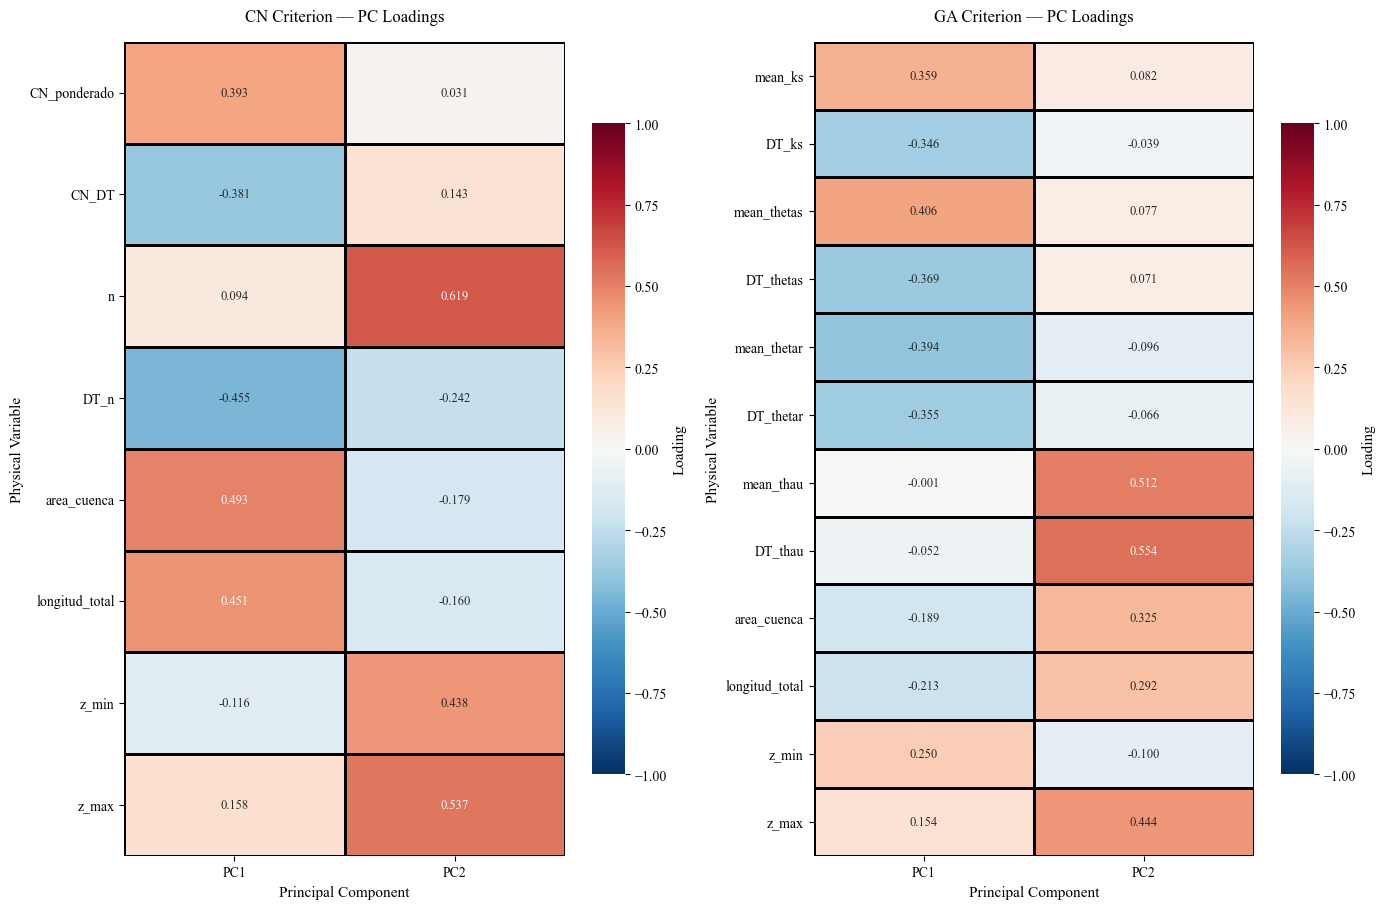

Loadings heatmaps saved to: loadings_heatmaps.png


In [14]:
# Create heatmaps for both criteria
fig, axes = plt.subplots(1, 2, figsize=(14, max(len(vars_cn), len(vars_ga)) * 0.6 + 2))

# CN loadings heatmap
sns.heatmap(loadings_cn, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
           vmin=-1, vmax=1, linewidths=1, linecolor='black',
           cbar_kws={'label': 'Loading', 'shrink': 0.8},
           ax=axes[0], annot_kws={'fontsize': 9})
axes[0].set_title('CN Criterion — PC Loadings', fontsize=12, weight='normal', pad=15)
axes[0].set_xlabel('Principal Component', fontsize=11)
axes[0].set_ylabel('Physical Variable', fontsize=11)
plt.setp(axes[0].get_yticklabels(), rotation=0)

# GA loadings heatmap
sns.heatmap(loadings_ga, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
           vmin=-1, vmax=1, linewidths=1, linecolor='black',
           cbar_kws={'label': 'Loading', 'shrink': 0.8},
           ax=axes[1], annot_kws={'fontsize': 9})
axes[1].set_title('GA Criterion — PC Loadings', fontsize=12, weight='normal', pad=15)
axes[1].set_xlabel('Principal Component', fontsize=11)
axes[1].set_ylabel('Physical Variable', fontsize=11)
plt.setp(axes[1].get_yticklabels(), rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(OUT_PATH, 'loadings_heatmaps.png'), dpi=300, bbox_inches='tight')
plt.show()
print('Loadings heatmaps saved to: loadings_heatmaps.png')

### PCA Biplots with Variable Vectors

Biplots combine the watershed scores (points) with variable loadings (arrows). Arrow direction and length indicate how each variable contributes to the principal components.

In [15]:
def create_biplot(pca, X_scaled, variables, cluster_labels, cluster_map, 
                 watershed_names, criterion, out_path):
    """
    Create PCA biplot with variable vectors.
    """
    COLORS = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', '#1ABC9C']
    
    # Get PCA transformation
    X_pca = pca.transform(X_scaled)
    var_exp = pca.explained_variance_ratio_ * 100
    loadings = pca.components_.T
    
    # Create figure
    fig, ax = plt.subplots(figsize=(14, 10))
    
    # Plot watershed points
    for i, (name, label) in enumerate(zip(watershed_names, cluster_labels)):
        color = COLORS[int(label) % len(COLORS)]
        ax.scatter(X_pca[i, 0], X_pca[i, 1], 
                  c=color, s=150, edgecolors='black', linewidths=1.2, 
                  alpha=0.7, zorder=10)
        ax.text(X_pca[i, 0], X_pca[i, 1], str(i+1), 
               ha='center', va='center', fontsize=9, 
               weight='bold', color='black', zorder=11)
    
    # Plot variable vectors (loadings scaled for visibility)
    scale_factor = 3.5
    for i, var in enumerate(variables):
        ax.arrow(0, 0, 
                loadings[i, 0] * scale_factor, 
                loadings[i, 1] * scale_factor,
                head_width=0.15, head_length=0.15, 
                fc='darkred', ec='darkred', 
                linewidth=2, alpha=0.8, zorder=5)
        # Add variable label
        ax.text(loadings[i, 0] * scale_factor * 1.15, 
               loadings[i, 1] * scale_factor * 1.15,
               var, fontsize=9, weight='bold',
               ha='center', va='center',
               bbox=dict(boxstyle='round,pad=0.4', 
                        facecolor='lightyellow', 
                        edgecolor='darkred', 
                        linewidth=1, alpha=0.9))
    
    # Axis properties
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}% explained variance)', fontsize=12, weight='bold')
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}% explained variance)', fontsize=12, weight='bold')
    ax.set_title(f'PCA Biplot with Variable Vectors — {criterion} Criterion', 
                fontsize=13, weight='normal', pad=15)
    ax.grid(True, alpha=0.2, linestyle=':', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Legend for watersheds
    legend_text = '\n'.join([f'{i+1:2d}. {name} (C{cluster_map[name]})' 
                            for i, name in enumerate(watershed_names)])
    ax.text(1.02, 0.5, legend_text, transform=ax.transAxes,
           fontsize=7, verticalalignment='center',
           bbox=dict(boxstyle='round,pad=0.6', facecolor='white', 
                    edgecolor='black', linewidth=0.8, alpha=0.95),
           family='monospace')
    
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Biplot saved to: {out_path}')

print('Creating biplots...')
print()

Creating biplots...



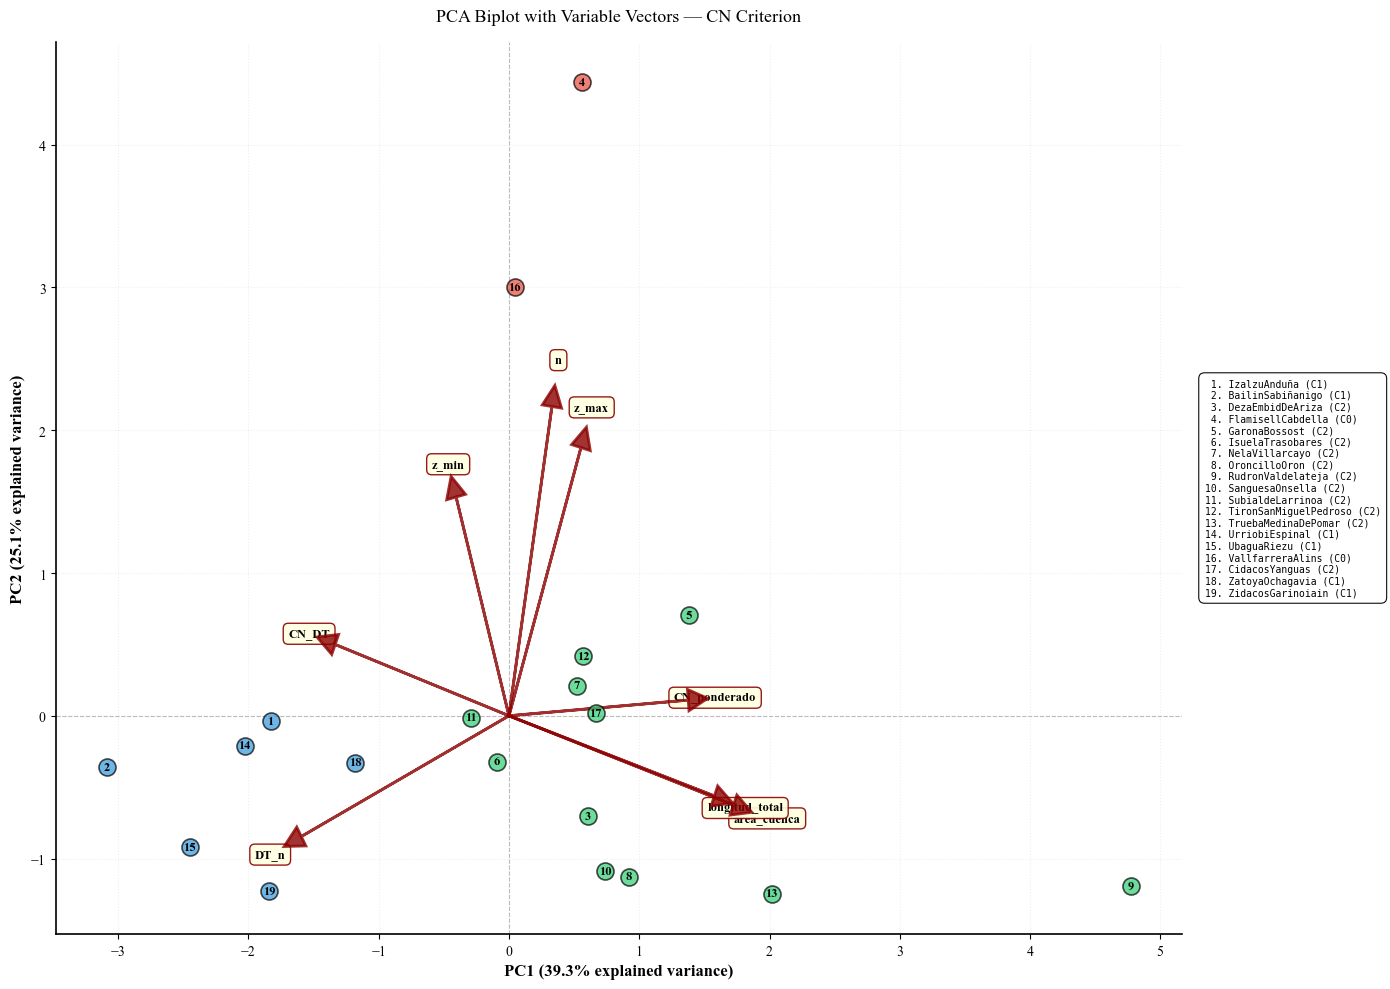

Biplot saved to: ../output/2_1-forced-clustering/cn_biplot.png


In [16]:
# Create CN biplot
scaler_cn = result_cn['scaler']
X_scaled_cn = scaler_cn.transform(df_phys[vars_cn])

create_biplot(
    pca=pca_cn,
    X_scaled=X_scaled_cn,
    variables=vars_cn,
    cluster_labels=result_cn['labels'],
    cluster_map=CN_MAP,
    watershed_names=df_phys.index.tolist(),
    criterion='CN',
    out_path=os.path.join(OUT_PATH, 'cn_biplot.png')
)

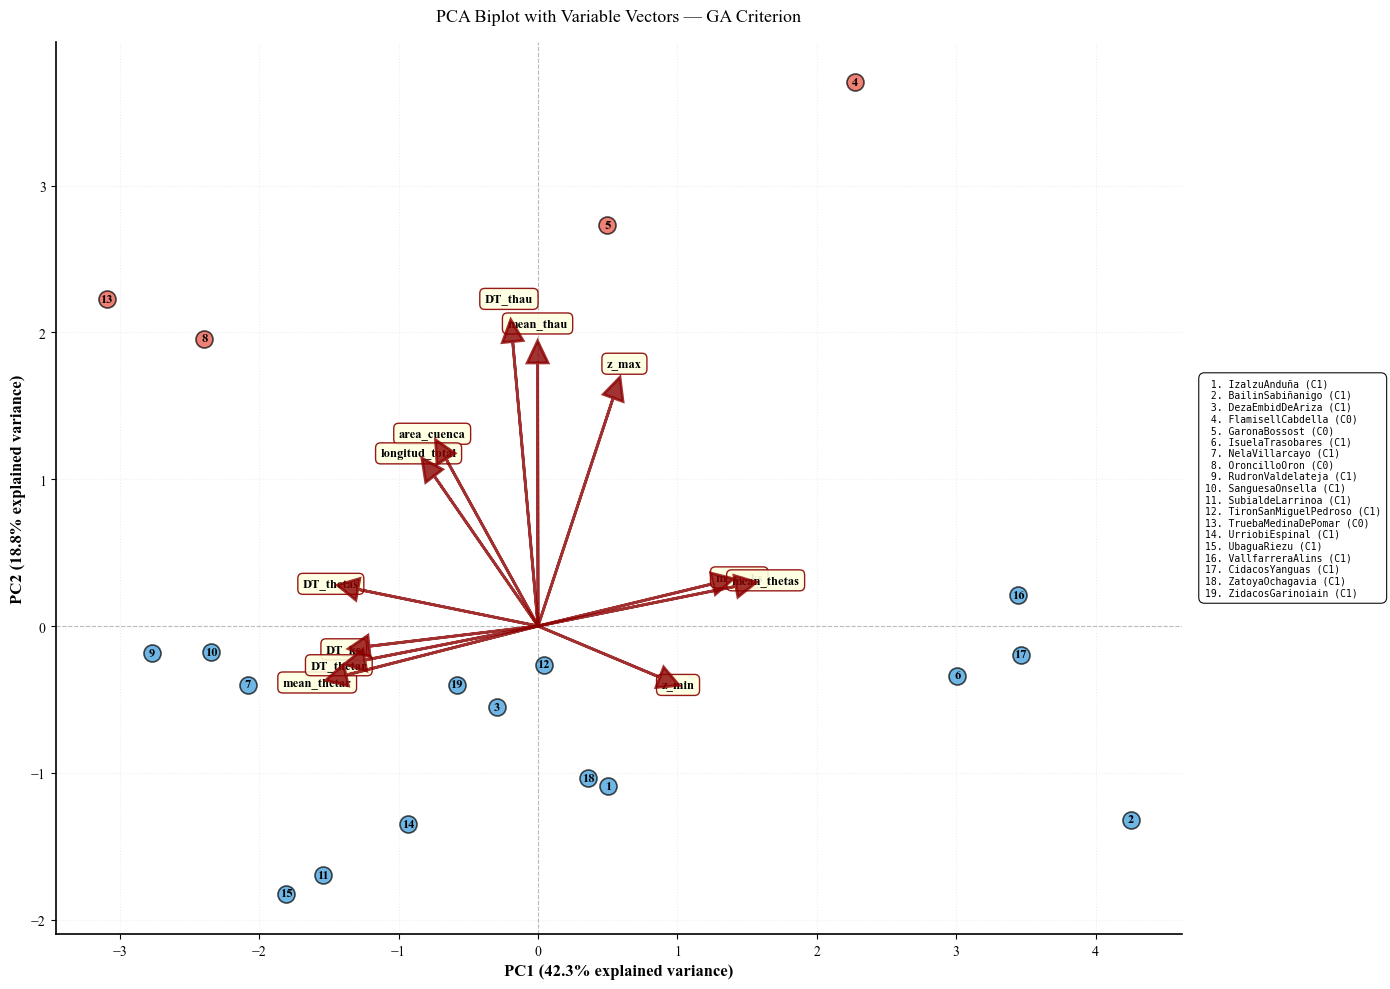

Biplot saved to: ../output/2_1-forced-clustering/ga_biplot.png


In [17]:
# Create GA biplot
scaler_ga = result_ga['scaler']
X_scaled_ga = scaler_ga.transform(df_phys[vars_ga])

create_biplot(
    pca=pca_ga,
    X_scaled=X_scaled_ga,
    variables=vars_ga,
    cluster_labels=result_ga['labels'],
    cluster_map=GA_MAP,
    watershed_names=df_phys.index.tolist(),
    criterion='GA',
    out_path=os.path.join(OUT_PATH, 'ga_biplot.png')
)

### Interpretation Guide

#### Understanding Loadings:
- **High positive loading**: Variable increases strongly with the PC
- **High negative loading**: Variable decreases strongly with the PC
- **Near-zero loading**: Variable has little influence on the PC

#### Understanding Biplots:
- **Arrow direction**: Indicates the direction of increase for that variable
- **Arrow length**: Indicates the strength of the variable's contribution
- **Arrow angle**: Small angles between arrows indicate correlated variables
- **Opposite arrows**: Indicate negatively correlated variables
- **Perpendicular arrows**: Indicate uncorrelated variables

#### Files Generated:
- `cn_loadings.csv` — CN loadings table
- `ga_loadings.csv` — GA loadings table
- `loadings_heatmaps.png` — Combined heatmaps
- `cn_biplot.png` — CN biplot with vectors
- `ga_biplot.png` — GA biplot with vectors

All files saved to: `notebooks/output/2_1-forced-clustering/`